In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/construction_cost_estimation_dataset.csv")
df.head()

,project_id,year,district,building_type,construction_area_sqft,num_floors,bedrooms,bathrooms,construction_quality,foundation_type,material_price_index,labor_rate_per_sqft,site_condition,project_duration_months,total_construction_cost_inr
0,TS-SYN-000001,2024,Medchal-Malkajgiri,Apartment,840,5,2,2,Premium,Pile,149.7,733,Sloped,11,4614000
1,TS-SYN-000002,2022,Rangareddy,Duplex,4380,2,8,7,Basic,Shallow,136.5,412,Normal,11,7711000
2,TS-SYN-000003,2025,Hyderabad,Independent House,1180,1,2,3,Standard,Shallow,149.8,698,Normal,5,3913000
3,TS-SYN-000004,2024,Nalgonda,Independent House,2100,1,5,4,Basic,Shallow,143.5,360,Normal,7,3574000
4,TS-SYN-000005,2018,Hyderabad,Independent House,1340,1,4,5,Standard,Shallow,106.1,453,Sloped,7,2983000


In [ ]:
missing_values = df.isnull().sum()

print("Missing values in dataset:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in dataset:
project_id                     0
year                           0
district                       0
building_type                  0
construction_area_sqft         0
num_floors                     0
bedrooms                       0
bathrooms                      0
construction_quality           0
foundation_type                0
material_price_index           0
labor_rate_per_sqft            0
site_condition                 0
project_duration_months        0
total_construction_cost_inr    0
dtype: int64

Total missing values: 0


In [ ]:
duplicates = df.duplicated().sum()

print("Total duplicate rows:", duplicates)

Total duplicate rows: 0


In [ ]:
numeric_columns = df.select_dtypes(include="number").columns

print("Negative values in each column:")
print((df[numeric_columns] < 0).sum())

Negative values in each column:
year                           0
construction_area_sqft         0
num_floors                     0
bedrooms                       0
bathrooms                      0
material_price_index           0
labor_rate_per_sqft            0
project_duration_months        0
total_construction_cost_inr    0
dtype: int64


In [ ]:
print("Invalid year:", (~df["year"].between(2018, 2025)).sum())

print("Invalid construction area:", (df["construction_area_sqft"] <= 0).sum())

print("Invalid floors:", (df["num_floors"] < 1).sum())

print("Invalid bedrooms:", (df["bedrooms"] < 0).sum())

print("Invalid bathrooms:", (df["bathrooms"] < 0).sum())

print("Invalid construction cost:", (df["total_construction_cost_inr"] <= 0).sum())

Invalid year: 0
Invalid construction area: 0
Invalid floors: 0
Invalid bedrooms: 0
Invalid bathrooms: 0
Invalid construction cost: 0


In [ ]:
text_columns = df.select_dtypes(include="object").columns

for column in text_columns:
    extra_spaces = (df[column] != df[column].str.strip()).sum()
    print(column, ":", extra_spaces)

project_id : 0
district : 0
building_type : 0
construction_quality : 0
foundation_type : 0
site_condition : 0


C:\Users\admmin\AppData\Local\Temp\ipykernel_25004\374833456.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


In [ ]:
output_file = "../data/processed/construction_cost_estimation_cleaned.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (12000, 15)


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   project_id                   12000 non-null  str    
 1   year                         12000 non-null  int64  
 2   district                     12000 non-null  str    
 3   building_type                12000 non-null  str    
 4   construction_area_sqft       12000 non-null  int64  
 5   num_floors                   12000 non-null  int64  
 6   bedrooms                     12000 non-null  int64  
 7   bathrooms                    12000 non-null  int64  
 8   construction_quality         12000 non-null  str    
 9   foundation_type              12000 non-null  str    
 10  material_price_index         12000 non-null  float64
 11  labor_rate_per_sqft          12000 non-null  int64  
 12  site_condition               12000 non-null  str    
 13  project_duration_months    

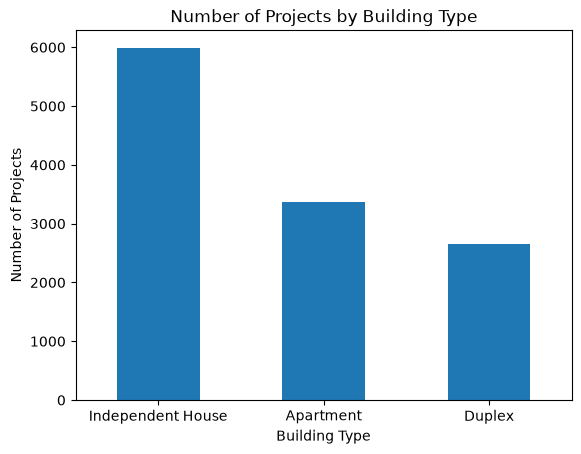

In [11]:
import matplotlib.pyplot as plt

df["building_type"].value_counts().plot(kind="bar")

plt.title("Number of Projects by Building Type")
plt.xlabel("Building Type")
plt.ylabel("Number of Projects")
plt.xticks(rotation=0)

plt.show()

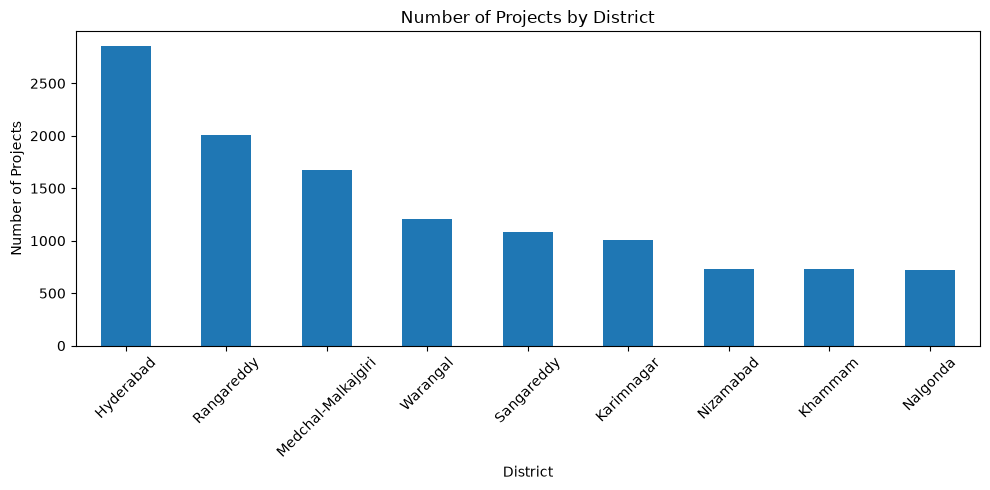

In [ ]:
district_counts = df["district"].value_counts()

district_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Number of Projects by District")
plt.xlabel("District")
plt.ylabel("Number of Projects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

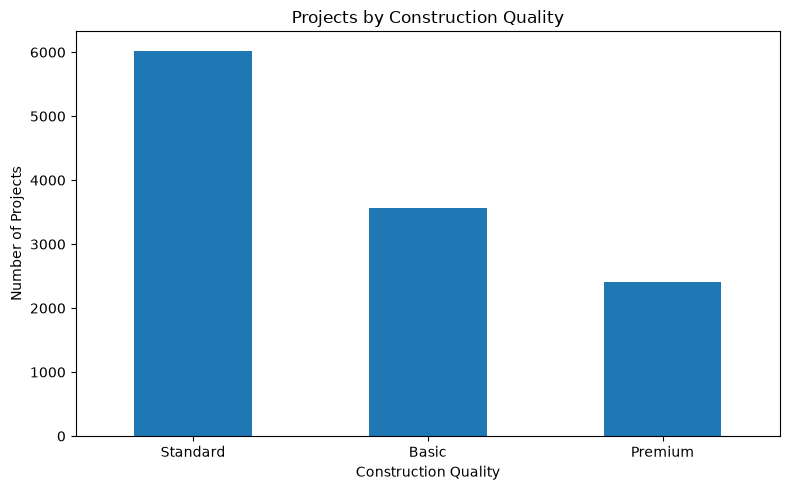

In [ ]:
quality_counts = df["construction_quality"].value_counts()

quality_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Projects by Construction Quality")
plt.xlabel("Construction Quality")
plt.ylabel("Number of Projects")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

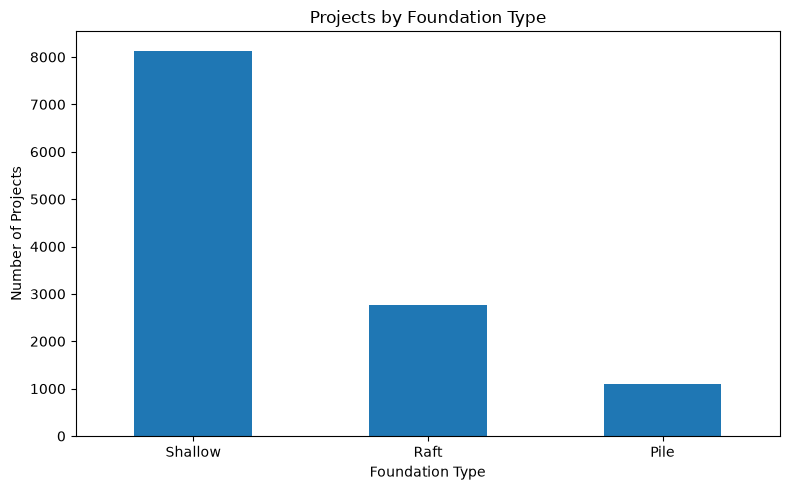

In [ ]:
foundation_counts = df["foundation_type"].value_counts()

foundation_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Projects by Foundation Type")
plt.xlabel("Foundation Type")
plt.ylabel("Number of Projects")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

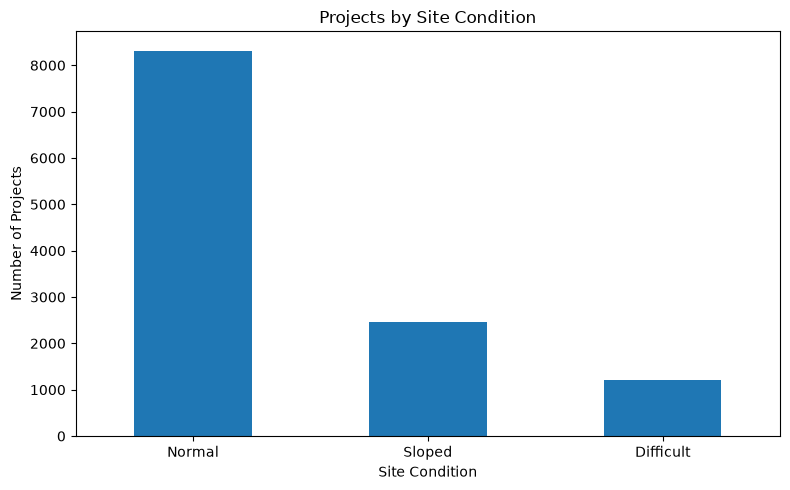

In [ ]:
site_counts = df["site_condition"].value_counts()

site_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Projects by Site Condition")
plt.xlabel("Site Condition")
plt.ylabel("Number of Projects")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

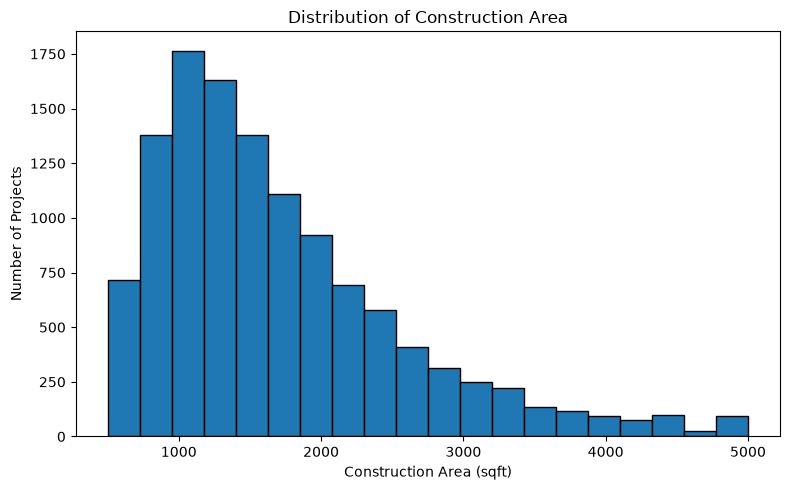

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df["construction_area_sqft"], bins=20, edgecolor="black")

plt.title("Distribution of Construction Area")
plt.xlabel("Construction Area (sqft)")
plt.ylabel("Number of Projects")

plt.tight_layout()
plt.show()

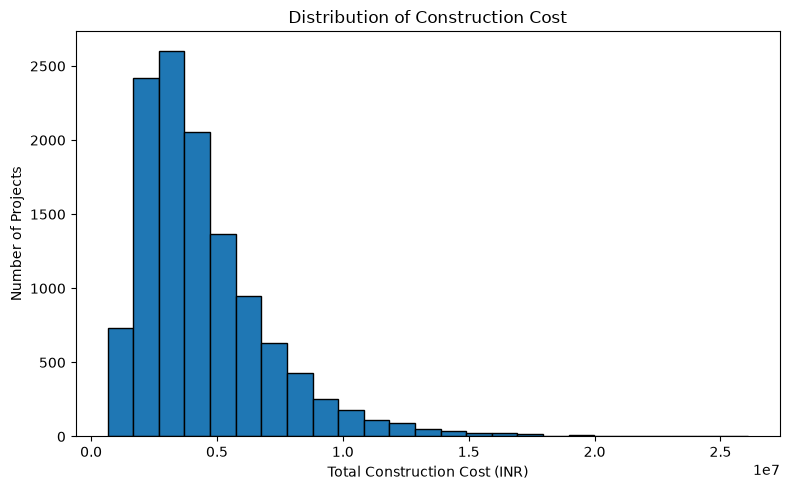

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["total_construction_cost_inr"],
    bins=25,
    edgecolor="black"
)

plt.title("Distribution of Construction Cost")
plt.xlabel("Total Construction Cost (INR)")
plt.ylabel("Number of Projects")

plt.tight_layout()
plt.show()

In [19]:
print("Minimum cost:", df["total_construction_cost_inr"].min())

print("Maximum cost:", df["total_construction_cost_inr"].max())

print("Average cost:", df["total_construction_cost_inr"].mean())

print("Median cost:", df["total_construction_cost_inr"].median())

Minimum cost: 657000
Maximum cost: 26094000
Average cost: 4484748.0
Median cost: 3808500.0


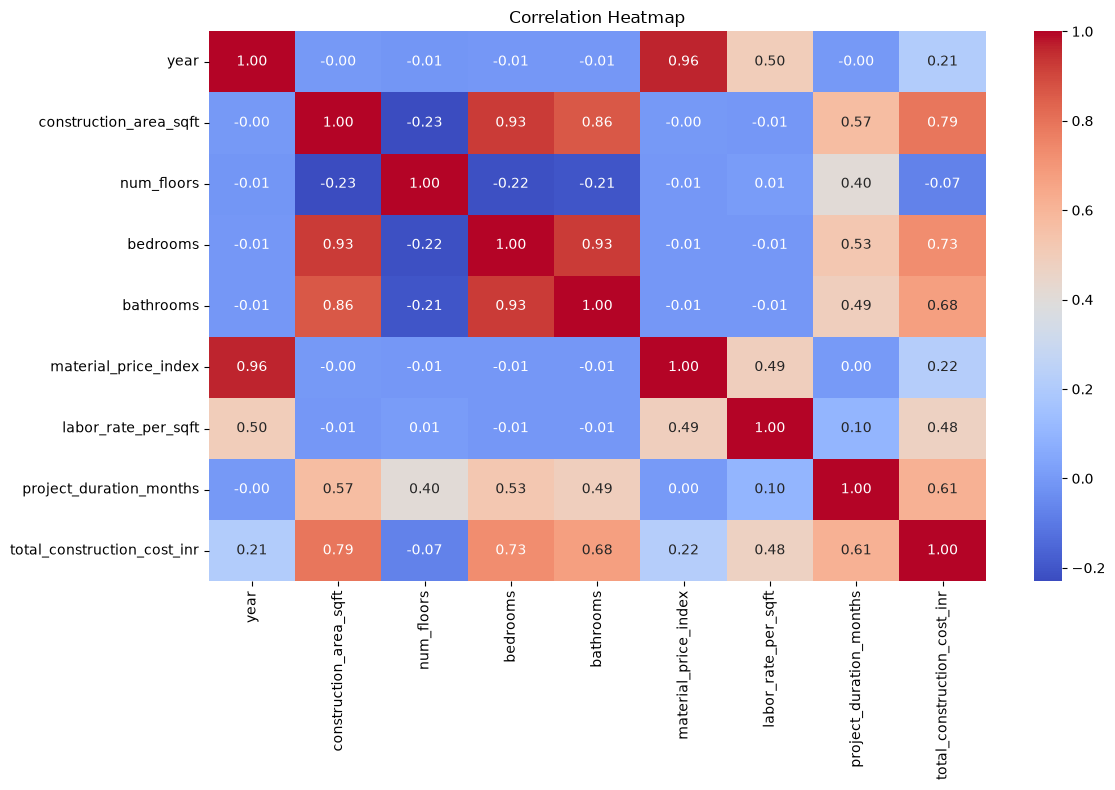

In [20]:
import seaborn as sns

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [21]:
cost_correlation = numeric_df.corr()["total_construction_cost_inr"]

print(cost_correlation.sort_values(ascending=False))

total_construction_cost_inr    1.000000
construction_area_sqft         0.788797
bedrooms                       0.730337
bathrooms                      0.677851
project_duration_months        0.612153
labor_rate_per_sqft            0.476025
material_price_index           0.218720
year                           0.210981
num_floors                    -0.074670
Name: total_construction_cost_inr, dtype: float64
